In [ ]:
# Imports and data directory
from pathlib import Path
import os
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
from melon_pkg.plotting import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "01_Mouse_E15_5"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."

OUTPUT = repo / "results/mouse_e15_brain"
OUTPUT.mkdir(parents=True, exist_ok=True)


In [ ]:
# Input data
from melon_pkg.cli_run import load_custom_h5, normalize_df, tfidf_lsi_modality

modalities = ["RNA", "ATAC"]
rna = load_custom_h5(DATA / "02_model_inputs/MELON/mRNA_data.h5", "gene")
atac = load_custom_h5(DATA / "02_model_inputs/MELON/ATAC_data.h5", "peak")
coords = pd.read_csv(DATA / "01_source_data/coords.csv", index_col=0)
barcodes = rna.index.intersection(atac.index, sort=False).intersection(coords.index, sort=False)
coords = coords.loc[barcodes, ["x", "y"]]

rna = normalize_df(rna.loc[barcodes], "RNA", target_sum=1e4)
atac = tfidf_lsi_modality(
    atac.loc[barcodes], label="ATAC", n_components=50, seed=42,
    drop_first=False, standardize=False,
)
features = [rna.to_numpy(dtype=np.float32), atac.to_numpy(dtype=np.float32)]


In [ ]:
# Parameters
config = {
    'epochs': 100,
    'batch_size': 2048,
    'embed_dim': 128,
    'training_seed': 42,
    'learning_rate': 0.001,
    'weight_decay': 1e-05,
    'temperature': 0.1,
    'training_spatial_k': 16,
    'export_spatial_k': 16,
    'augment_p': 0.8,
    'augmentations': ['gaussian_noise', 'feature_dropout', 'neighbor_mix'],
    'shuffle_batches': False,
    'clustering_seed': 2025,
    'target_clusters': 12,
    'clustering_neighbors': 10,
    'leiden_resolution': 1.0,
}


In [ ]:
# Spatial graph and augmented views
import torch
from torch import nn
from types import MethodType
import pytorch_lightning as pl
from melon_pkg.data import DualAugDataModule, SpatialOmicsAugmentations
from melon_pkg.model import SpotTokenAdapter
from melon_pkg.models.mmfusion import MMFusion
from melon_pkg.pl_modules.melon import MELONModel
from melon_pkg.utils import build_knn_mask
from melon_pkg.embedding import export_embedding

pl.seed_everything(config["training_seed"], workers=True)
tensors = [torch.tensor(x, dtype=torch.float32) for x in features]
xy = torch.as_tensor(coords.to_numpy(), dtype=torch.float32)
mask, weights = build_knn_mask(xy, k=config["training_spatial_k"],
                               include_self=True, return_weights=True, symmetric=True)
augmentation = SpatialOmicsAugmentations
aug = dict(augmentations=config["augmentations"], p=config["augment_p"])
data = DualAugDataModule(
    mods_raw=tensors, coords=xy, neighbor_mask=mask, neighbor_weight=weights,
    augmentA=augmentation(**aug), augmentB=augmentation(**aug),
    batch_size=config["batch_size"], shuffle=config["shuffle_batches"],
    spot_tokenization=True,
)


In [ ]:
# MELON model
dim = config["embed_dim"]
encoder = MMFusion(
    encoders=[nn.Sequential(nn.Linear(x.shape[1], dim), nn.ReLU(), nn.Linear(dim, dim))
              for x in tensors],
    input_adapters=[SpotTokenAdapter() for _ in tensors],
    embed_dim=dim, fusion="concat", pool="tokens", n_heads=8, n_layers=1,
)
model = MELONModel(
    encoder=encoder, projection=MELONModel._build_mlp(dim, 256, dim),
    optim_kwargs={"lr": config["learning_rate"], "weight_decay": config["weight_decay"]},
    loss_kwargs={"temperature": config["temperature"]},
    neighborhood_cfg={"hidden_dim": 64, "heads": 8, "dropout": 0.1,
                      "k_neighbors": config["training_spatial_k"], "include_self": True},
)
def configure_optimizers(self):
    return torch.optim.Adam(self.parameters(), **self.optim_kwargs, betas=(0.9, 0.999))
model.configure_optimizers = MethodType(configure_optimizers, model)


In [ ]:
# Train and embed
trainer = pl.Trainer(max_epochs=config["epochs"], accelerator="cpu", devices=1,
                     logger=False, enable_checkpointing=False, deterministic=True)
trainer.fit(model, datamodule=data)
embedding = pd.DataFrame(
    export_embedding(model, tensors, xy, spatial_k=config["export_spatial_k"]),
    index=coords.index,
)
display({"spots": len(embedding), "embedding_dimensions": embedding.shape[1]})


{'spots': 1949, 'embedding_dimensions': 128}

In [ ]:
# Spatial clustering
from melon_pkg.cli_cluster import leiden_clustering
labels = leiden_clustering(
    embedding.to_numpy(), n_clusters=config["target_clusters"],
    n_neighbors=config["clustering_neighbors"], seed=config["clustering_seed"],
    resolution=config["leiden_resolution"],
)
domains = pd.Series(labels, index=embedding.index, name="MELON")
display({"spatial_domains": domains.nunique()})


{'spatial_domains': 12}

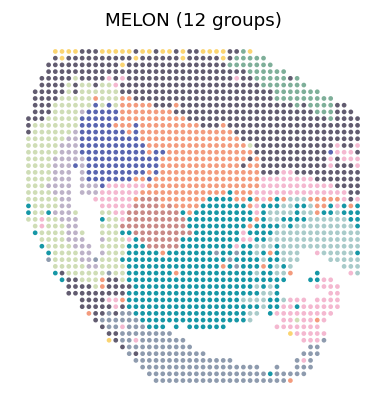

In [ ]:
# Spatial plot
plot_data = coords.loc[embedding.index].copy()
plot_data["MELON"] = domains
show(spatial_panels(plot_data, ["MELON"], ncols=1))


In [ ]:
# Gene expression inputs
import anndata as ad
import scanpy as sc
from scipy import sparse

rna = ad.read_h5ad(DATA / "02_model_inputs/downstream/rna_log1p.h5ad")
rna = rna[embedding.index].copy()
domain_display = {0: 9, 1: 7, 2: 1, 3: 11, 4: 8, 5: 3, 6: 10, 7: 4, 8: 12, 9: 2, 10: 6, 11: 5}
style = {
    "domain_order": [9, 7, 6, 5, 1, 11, 8, 3, 10, 4, 12, 2],
    "domain_colors": dict(zip(map(str, range(1, 13)), PAPER_COLORS[:12])),
}
rna.obs["MELON"] = domains.loc[rna.obs_names].astype(str).astype("category")
expression = coords.loc[rna.obs_names].copy()
expression["domain"] = domains.loc[expression.index].map(domain_display)
expression[["Col1a1", "Neurod2"]] = rna[:, ["Col1a1", "Neurod2"]].to_df()
expression.to_csv(OUTPUT / "marker_expression.csv", index_label="barcode")


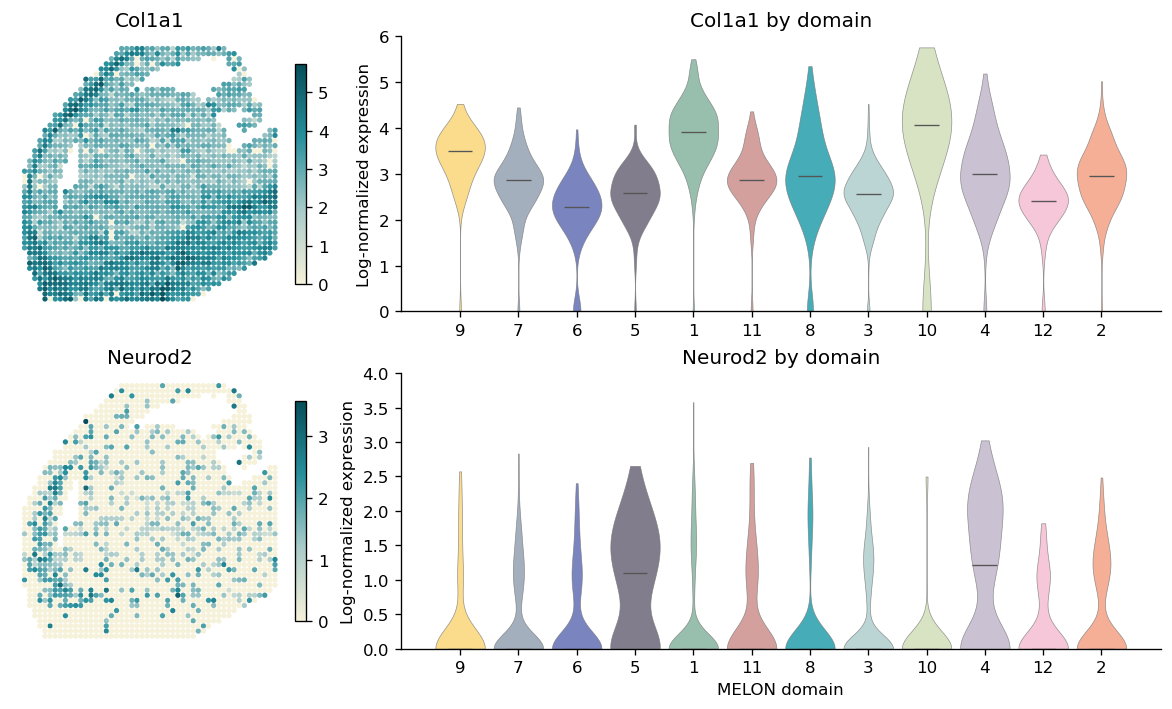

In [ ]:
# Marker expression
expression = read_indexed(OUTPUT / "marker_expression.csv")
show(marker_expression_panels(expression, style))


In [ ]:
# Differential expression
sc.tl.rank_genes_groups(rna, "MELON", method="wilcoxon",
                       corr_method="benjamini-hochberg", pts=True)
markers = pd.concat([
    sc.get.rank_genes_groups_df(rna, group=domain).assign(domain=int(domain))
    for domain in rna.obs["MELON"].cat.categories
], ignore_index=True)
top_markers = markers.loc[(markers.logfoldchanges > 0) & (markers.pvals_adj < 0.05)]
top_markers = top_markers.groupby("domain", group_keys=False).head(100)
markers.to_csv(OUTPUT / "markers_all.csv", index=False)
top_markers.to_csv(OUTPUT / "markers_top100.csv", index=False)


In [ ]:
# Pathway enrichment
import requests

top_markers = pd.read_csv(OUTPUT / "markers_top100.csv")
queries = {str(domain): group.names.tolist() for domain, group in top_markers.groupby("domain")}
enrichment_config = {
    "organism": "mmusculus", "sources": ["GO:BP", "REAC"],
    "user_threshold": 0.05, "significance_threshold_method": "g_SCS", "no_evidences": True,
}
response = requests.post("https://biit.cs.ut.ee/gprofiler/api/gost/profile/",
                         json=dict(enrichment_config, query=queries), timeout=180)
response.raise_for_status()
enrichment = pd.DataFrame(response.json()["result"])
enrichment["raw_domain"] = enrichment["query"].astype(int)
enrichment["domain"] = enrichment.raw_domain.map(domain_display)
assert enrichment.domain.notna().all()
enrichment["neg_log10_p"] = -np.log10(enrichment.p_value.clip(lower=1e-300))
pathways = ["synapse organization", "nervous system development", "neuron differentiation",
            "generation of neurons", "multicellular organism development"]
enrichment_matrix = enrichment.pivot_table(index="domain", columns="name", values="neg_log10_p", aggfunc="max")
enrichment_matrix = enrichment_matrix.reindex(
    index=[domain_display[d] for d in sorted(domain_display)], columns=pathways,
).fillna(0)
enrichment.to_csv(OUTPUT / "domain_enrichment.csv", index=False)
enrichment_matrix.to_csv(OUTPUT / "enrichment_matrix.csv")


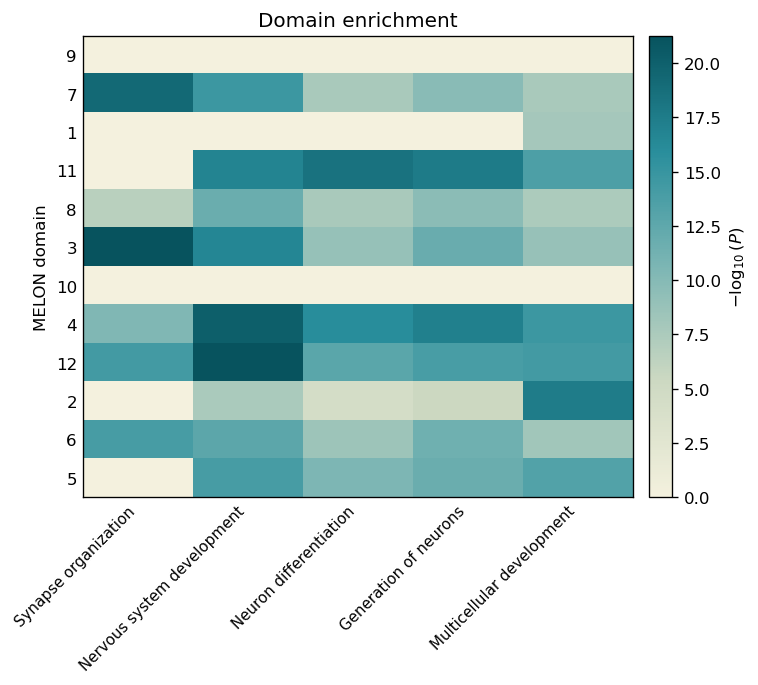

In [ ]:
# Domain enrichment
enrichment_matrix = pd.read_csv(OUTPUT / "enrichment_matrix.csv", index_col=0)
show(domain_enrichment_panel(enrichment_matrix))


In [ ]:
# Embedding layout and spatial adjacency
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import kneighbors_graph

tsne_config = dict(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=42)
scaled = StandardScaler().fit_transform(embedding.to_numpy(dtype=float))
reduced = PCA(n_components=30, random_state=42).fit_transform(scaled)
tsne = pd.DataFrame(TSNE(**tsne_config).fit_transform(reduced),
                    index=embedding.index, columns=["TSNE1", "TSNE2"])
tsne["domain"] = domains.loc[tsne.index].map(domain_display)
graph = kneighbors_graph(coords.loc[embedding.index].to_numpy(), n_neighbors=6,
                         mode="connectivity", include_self=False)
graph = sparse.triu(graph.maximum(graph.T), k=1).tocoo()
domain_values = tsne.domain.to_numpy()
edges = pd.DataFrame({"source": domain_values[graph.row], "target": domain_values[graph.col]})
edges[["source", "target"]] = np.sort(edges[["source", "target"]].to_numpy(), axis=1)
edges = edges.groupby(["source", "target"]).size().rename("edge_count").reset_index()
tsne.to_csv(OUTPUT / "tsne.csv", index_label="barcode")
edges.to_csv(OUTPUT / "domain_edges.csv", index=False)


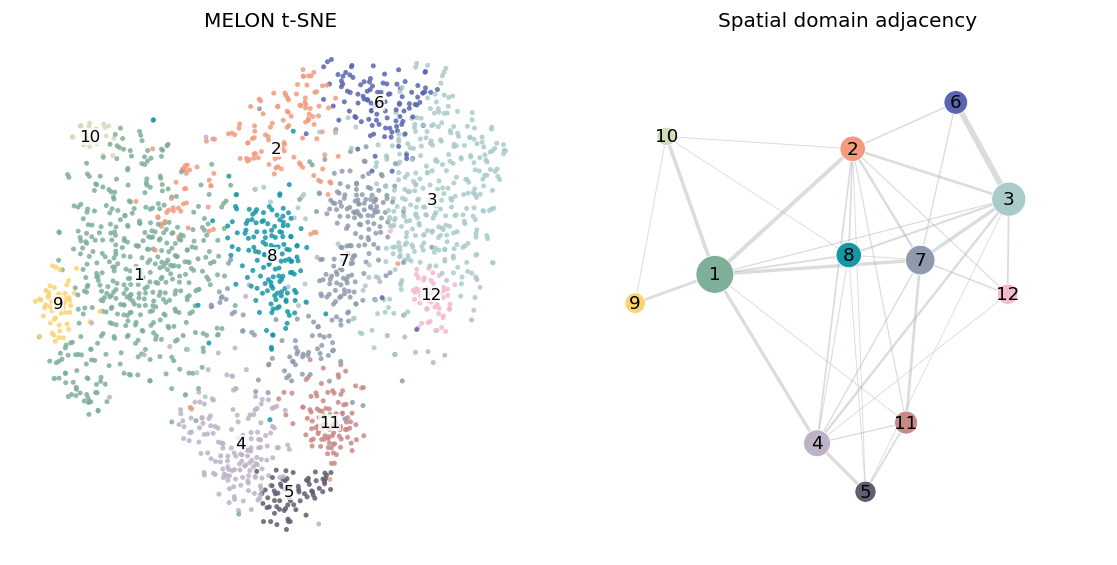

In [ ]:
# MELON domains and adjacency
tsne = read_indexed(OUTPUT / "tsne.csv")
edges = pd.read_csv(OUTPUT / "domain_edges.csv")
show(domain_network_panels(tsne, edges, style))


In [ ]:
# Decoder inputs and parameters
from melon_pkg.decoder import (
    set_seed, fit_decoder, extract_decoder_outputs, specificity_weights, row_profile_matrix,
    positive_standardized_support, positive_binary_residual_support, compute_pair_activity,
)

with np.load(DATA / "02_model_inputs/downstream/decoder_inputs.npz", allow_pickle=False) as inputs:
    input_barcodes = inputs["barcodes"].astype(str)
    decoder_rna = pd.DataFrame(inputs["RNA"], index=input_barcodes, columns=inputs["genes"].astype(str))
    decoder_atac = pd.DataFrame(inputs["ATAC"], index=input_barcodes, columns=inputs["peaks"].astype(str))
decoder_rna = decoder_rna.loc[embedding.index]
decoder_atac = decoder_atac.loc[embedding.index]
decoder_config = {
    "n_factors": 24, "hidden_dim": 48, "batch_size": 256, "epochs": 20,
    "lr": 0.001, "weight_decay": 1e-5, "atac_weight": 1.0,
    "l1_weight": 0.0001, "activity_weight": 0.0001,
    "factor_decorrelation_weight": 0.01, "val_frac": 0.1, "seed": 42,
}
specificity_power = 0.5


In [ ]:
# Fit the pair decoder
set_seed(decoder_config["seed"])
decoder_model, decoder_history, split = fit_decoder(
    embedding.to_numpy(np.float32), decoder_rna.to_numpy(np.float32),
    decoder_atac.to_numpy(np.float32), **decoder_config,
)
decoded = extract_decoder_outputs(decoder_model, embedding.to_numpy(np.float32))
h = pd.DataFrame(decoded.h, index=embedding.index)
wr = pd.DataFrame(decoded.rna_loadings, index=decoder_rna.columns)
wa = pd.DataFrame(decoded.atac_loadings, index=decoder_atac.columns)
torch.save(decoder_model.state_dict(), OUTPUT / "decoder.pt")
decoder_history.to_csv(OUTPUT / "decoder_training.csv", index=False)
h.to_csv(OUTPUT / "spot_factor_usage.csv", index_label="barcode")
wr.to_csv(OUTPUT / "rna_factor_loadings.csv", index_label="gene")
wa.to_csv(OUTPUT / "atac_factor_loadings.csv", index_label="peak")


In [ ]:
# External reference validation
from sklearn.metrics import roc_auc_score, roc_curve

h = read_indexed(OUTPUT / "spot_factor_usage.csv")
wr = read_indexed(OUTPUT / "rna_factor_loadings.csv")
wa = read_indexed(OUTPUT / "atac_factor_loadings.csv")
gene_weights = pd.Series(specificity_weights((decoder_rna > 0.1).mean(0), specificity_power), index=decoder_rna.columns)
peak_weights = pd.Series(specificity_weights(decoder_atac.mean(0), specificity_power), index=decoder_atac.columns)
weighted_rna = wr.to_numpy(np.float32) * gene_weights.loc[wr.index].to_numpy()[:, None]
weighted_atac = wa.to_numpy(np.float32) * peak_weights.loc[wa.index].to_numpy()[:, None]
rna_profiles, _ = row_profile_matrix(wr.to_numpy(np.float32))
atac_profiles, _ = row_profile_matrix(wa.to_numpy(np.float32))
score_matrices = {"scHiCAR": weighted_rna @ weighted_atac.T, "Brain2023": rna_profiles @ atac_profiles.T}
metrics = []
for reference, scores in score_matrices.items():
    pairs = pd.read_csv(DATA / f"01_source_data/external_references/{reference}_pairs.csv")
    gene_index = wr.index.get_indexer(pairs.gene)
    peak_index = wa.index.get_indexer(pairs.peak)
    assert (gene_index >= 0).all() and (peak_index >= 0).all()
    pairs["MELON_score"] = scores[gene_index, peak_index]
    y = pairs.reference_supported.astype(bool)
    fpr, tpr, thresholds = roc_curve(y, pairs.MELON_score)
    auc = roc_auc_score(y, pairs.MELON_score)
    metrics.append({"reference": reference, "AUROC": auc, "pairs": len(pairs), "supported": int(y.sum())})
    pairs.to_csv(OUTPUT / f"{reference}_scores.csv", index=False)
    pd.DataFrame({"FPR": fpr, "TPR": tpr, "threshold": thresholds}).to_csv(
        OUTPUT / f"{reference}_roc.csv", index=False,
    )
pd.DataFrame(metrics).to_csv(OUTPUT / "reference_metrics.csv", index=False)


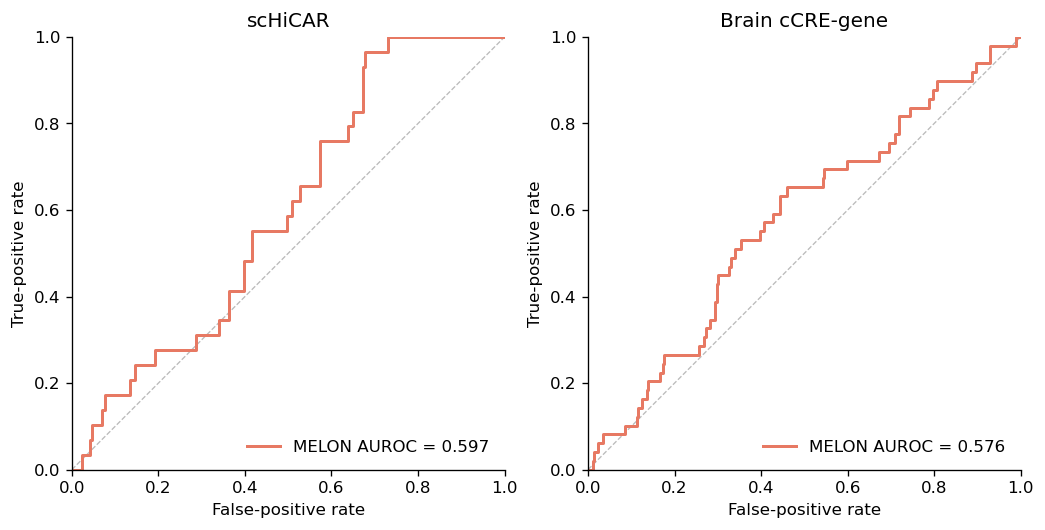

In [ ]:
# MELON ROC curves
metrics = pd.read_csv(OUTPUT / "reference_metrics.csv").set_index("reference")
curves = {reference: (pd.read_csv(OUTPUT / f"{reference}_roc.csv"), metrics.loc[reference, "AUROC"])
          for reference in ["scHiCAR", "Brain2023"]}
show(regulatory_roc_panels(curves))


In [ ]:
# Gene-peak activity
selected_pairs = {"Myl4": "chr11-103697466-103697966", "Neurod2": "chr11-98963508-98964008"}
gene_support = pd.DataFrame(positive_standardized_support(decoder_rna.to_numpy(np.float32)),
                            index=decoder_rna.index, columns=decoder_rna.columns)
peak_support = pd.DataFrame(positive_binary_residual_support(decoder_atac.to_numpy(np.float32)),
                            index=decoder_atac.index, columns=decoder_atac.columns)
for gene, peak in selected_pairs.items():
    pair_map = coords.loc[h.index].copy()
    pair_map["gene_expr"] = decoder_rna.loc[h.index, gene]
    pair_map["peak_acc"] = decoder_atac.loc[h.index, peak]
    pair_map["pair_activity"] = compute_pair_activity(
        h, wr, wa, gene_weights, peak_weights, gene_support, peak_support, gene, peak,
    )
    pair_map.to_csv(OUTPUT / f"pair_activity_{gene}.csv", index_label="barcode")


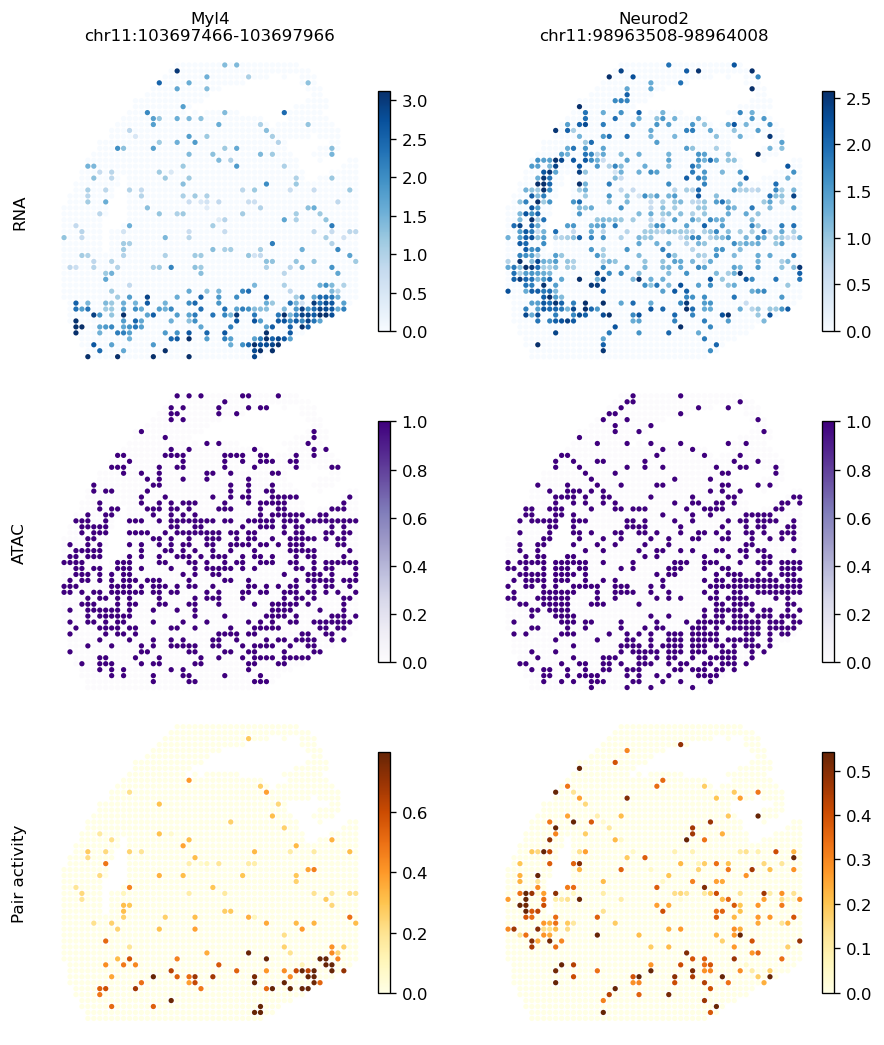

In [ ]:
# Spatial gene-peak activity
pair_maps = {gene: (peak, read_indexed(OUTPUT / f"pair_activity_{gene}.csv"))
             for gene, peak in selected_pairs.items()}
show(gene_peak_panels(pair_maps))
